# α-Synuclein BBB Virtual Screening — Stage A (v2, full workflow)

**Goal:** computationally prioritise BBB-positive small molecules for *later experimental (microfluidic) validation* against α-synuclein aggregation.

> ⚠️ **Scientific note.** Results are *computationally prioritised BBB-positive small molecules proposed for experimental validation.* Docking does **not** prove binding, inhibition, real BBB penetration or therapeutic effect. Nothing here is a Parkinson's treatment or cure.

**Pipeline**

1. SETUP → 2. DATA (B3DB) → 3. BBB filter → 4. chemical quality filter → 5. relevance + diversity prioritisation
2. Stage-1 docking (primary fibril) → 7. Top 10–20 → 8. 3-polymorph docking (6H6B, 6CU8, 6RT0)
3. **A. High-performance Top 3** → 10. cost / practicality → **B. Cost-effective Top 3** → 12. PDF report

**How to run**

- Colab → *Runtime ▸ Run all* from a fresh runtime. If Colab asks to restart after the install cell, restart, then run all again.
- Step 1: set `MODE = "SMOKE"` once, to debug only. Its outputs are labelled `SMOKE_ONLY` and are **not scientific results**.
- Step 2: set `MODE = "STANDARD"` (default) for the real screen. Use `EXTENDED` for a larger library.
- Docking is slow on Colab CPUs. The run is **resumable**: finished dockings are saved and skipped on re-run (set `USE_DRIVE = True` to keep them across disconnects).
- Prices are **never invented**. See section 10 for the price-entry step.

## 1 · SETUP

In [1]:
%%bash
set -e
apt-get -qq update > /dev/null
apt-get -qq install -y openbabel > /dev/null
pip -q install rdkit meeko biopython reportlab pandas numpy scipy matplotlib requests tqdm
mkdir -p /content/bin
if [ ! -x /content/bin/vina ]; then
  wget -q -O /content/bin/vina https://github.com/ccsb-scripps/AutoDock-Vina/releases/download/v1.2.5/vina_1.2.5_linux_x86_64 || true
  chmod +x /content/bin/vina || true
fi
if ! /content/bin/vina --version > /dev/null 2>&1; then
  apt-get -qq install -y autodock-vina > /dev/null
  ln -sf "$(which vina)" /content/bin/vina
fi
/content/bin/vina --version
obabel -V

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 41.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 86.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 75.5 MB/s eta 0:00:00
AutoDock Vina v1.2.5
Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 2 · CONFIGURATION (edit only this cell)

In [2]:
# ----------------------------- USER SETTINGS -----------------------------
MODE        = "STANDARD"     # "SMOKE" = debug only | "STANDARD" = final | "EXTENDED" = bigger final
PRIMARY_PDB = "6H6B"         # fibril used for Stage-1 screening
PDB_IDS     = ["6H6B", "6CU8", "6RT0"]
SEED        = 42
USE_DRIVE   = False          # True = save everything to Google Drive (survives disconnects)

MODE_SETTINGS = {
    #            Stage-1 library | Stage-2 list (ONE list, both Top 3 sets come from it) | Vina exhaustiveness (S1, S2)
    "SMOKE":    dict(n_stage1=8,    n_stage2=6,  exh1=4, exh2=8),
    "STANDARD": dict(n_stage1=600,  n_stage2=20, exh1=8, exh2=24),
    "EXTENDED": dict(n_stage1=2000, n_stage2=20, exh1=8, exh2=32),
}

# Objective weights (all visible, all editable)
W_HP = dict(affinity=0.35, consistency=0.15, pose=0.15, region=0.10, ligand_eff=0.15, bbb_evidence=0.10)
W_COST_NOPRICE = dict(performance=0.55, availability=0.25, simplicity=0.20)
W_COST_PRICE   = dict(performance=0.40, availability=0.20, simplicity=0.15, price=0.25)
DIVERSITY_MAX_TANIMOTO = 0.60    # final picks must differ from each other (Morgan r=2)
BOX_PAD, BOX_SLAB, BOX_CAP = 8.0, 30.0, 60.0   # Angstrom
CONTACT_CUTOFF = 4.5             # Angstrom, ligand-receptor contact
# --------------------------------------------------------------------------
assert MODE in MODE_SETTINGS, "MODE must be SMOKE, STANDARD or EXTENDED"
CFG = MODE_SETTINGS[MODE]
IS_SMOKE = (MODE == "SMOKE")
FILE_PREFIX = "SMOKE_ONLY_" if IS_SMOKE else ""
print("=" * 70)
print(f"MODE = {MODE}   ->   {'DEBUG ONLY - NOT A SCIENTIFIC RESULT' if IS_SMOKE else 'REAL SCREEN'}")
print(CFG)
print("=" * 70)
assert abs(sum(W_HP.values()) - 1) < 1e-9

MODE = STANDARD   ->   REAL SCREEN
{'n_stage1': 600, 'n_stage2': 20, 'exh1': 8, 'exh2': 24}


In [3]:
import os, sys, re, io, json, math, time, shutil, subprocess, threading, warnings, datetime, random
from collections import Counter
from pathlib import Path
from urllib.parse import urlparse
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd, requests
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from tqdm.auto import tqdm
from IPython.display import display, Markdown

import rdkit
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import AllChem, Descriptors, rdMolDescriptors, Crippen, Lipinski, Draw, rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.SimDivFilters import rdSimDivPickers
RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")
random.seed(SEED); np.random.seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = Path("/content/drive/MyDrive/alphasyn_screen")
else:
    BASE = Path("/content/alphasyn_screen")
WORK = BASE / MODE.lower()
D_REC, D_LIG, D_POSE, D_OUT, D_TEST = [WORK / n for n in ("receptors", "ligands", "poses", "outputs", "selftest")]
for d in (D_REC, D_LIG, D_POSE, D_OUT, D_TEST): d.mkdir(parents=True, exist_ok=True)

VINA = "/content/bin/vina" if os.access("/content/bin/vina", os.X_OK) else shutil.which("vina")
assert VINA, "AutoDock Vina not found - re-run the setup cell"
vina_ver = subprocess.run([VINA, "--version"], capture_output=True, text=True).stdout.strip()
obabel_ver = subprocess.run(["obabel", "-V"], capture_output=True, text=True).stdout.strip()
try:
    from importlib.metadata import version as _v
    meeko_ver = _v("meeko")
except Exception:
    meeko_ver = "unknown"
VERSIONS = dict(rdkit=rdkit.__version__, vina=vina_ver, openbabel=obabel_ver, meeko=meeko_ver,
                python=sys.version.split()[0], date=str(datetime.date.today()))
print(VERSIONS); print("Work folder:", WORK)

FUNNEL = []   # (step, count) for the report
CHECK_DATE = datetime.date.today().isoformat()

{'rdkit': '2026.09.1', 'vina': 'AutoDock Vina v1.2.5', 'openbabel': 'Open Babel 3.1.1 -- Mar 31 2024 -- 06:39:03', 'meeko': '0.8.0', 'python': '3.13.16', 'date': '2026-10-12'}
Work folder: /content/alphasyn_screen/standard


## 3 · DATA — load B3DB and keep BBB-positive molecules
Source: B3DB (Meng et al., *Sci Data* 2021), file `B3DB_classification.tsv` from the `theochem/B3DB` GitHub repo. Columns are **auto-detected and printed** so you can see what the current file really contains.

In [4]:
B3DB_URLS = [
    "https://raw.githubusercontent.com/theochem/B3DB/main/B3DB/B3DB_classification.tsv",
    "https://raw.githubusercontent.com/theochem/B3DB/master/B3DB/B3DB_classification.tsv",
]
def load_b3db():
    last = None
    for u in B3DB_URLS:
        try:
            r = requests.get(u, timeout=180); r.raise_for_status()
            print("Loaded:", u)
            return pd.read_csv(io.StringIO(r.text), sep="\t")
        except Exception as e:
            last = e; print("failed:", u, e)
    raise RuntimeError(f"Could not download B3DB: {last}")

def pick_col(df, candidates):
    low = {c.lower().strip(): c for c in df.columns}
    for c in candidates:
        if c.lower() in low: return low[c.lower()]
    return None

raw = load_b3db()
print("shape:", raw.shape); print("columns:", list(raw.columns))
COL = dict(
    smiles = pick_col(raw, ["SMILES", "smiles", "canonical_smiles"]),
    label  = pick_col(raw, ["BBB+/BBB-", "BBB", "label", "class"]),
    name   = pick_col(raw, ["compound_name", "name", "Name"]),
    cid    = pick_col(raw, ["CID", "cid", "PubChem_CID"]),
    group  = pick_col(raw, ["group", "Group"]),
)
print("detected columns:", COL)
assert COL["smiles"] and COL["label"], "B3DB layout changed: need a SMILES column and a BBB label column"

raw["_label"] = raw[COL["label"]].astype(str).str.strip().str.upper()
print(raw["_label"].value_counts())
if COL["group"]: print("evidence groups:\n", raw[COL["group"]].value_counts(dropna=False))

pos = raw[raw["_label"] == "BBB+"].copy()
pos["mol_id"] = [f"M{i:05d}" for i in pos.index]
pos = pos.rename(columns={COL["smiles"]: "smiles_raw"})
pos["name"] = pos[COL["name"]] if COL["name"] else ""
pos["group"] = pos[COL["group"]].astype(str) if COL["group"] else "NA"
def _cid(x):
    try: return str(int(float(x)))
    except Exception: return ""
pos["cid"] = pos[COL["cid"]].map(_cid) if COL["cid"] else ""
pos = pos[["mol_id", "name", "cid", "smiles_raw", "group"]].reset_index(drop=True)
FUNNEL += [("B3DB molecules (all)", len(raw)), ("BBB-positive", len(pos))]
print("BBB-positive molecules:", len(pos))

Loaded: https://raw.githubusercontent.com/theochem/B3DB/main/B3DB/B3DB_classification.tsv
shape: (7807, 12)
columns: ['NO.', 'compound_name', 'IUPAC_name', 'SMILES', 'CID', 'logBB', 'BBB+/BBB-', 'Inchi', 'threshold', 'reference', 'group', 'comments']
detected columns: {'smiles': 'SMILES', 'label': 'BBB+/BBB-', 'name': 'compound_name', 'cid': 'CID', 'group': 'group'}
_label
BBB+    4956
BBB-    2851
Name: count, dtype: int64
evidence groups:
 group
B    3621
C    3077
A    1058
D      51
Name: count, dtype: int64
BBB-positive molecules: 4956


## 4 · CHEMICAL / STRUCTURE QUALITY FILTERING
Each BBB+ molecule is cleaned (largest fragment, neutralised) and must pass **objective** rules:

- valid structure; only C, H, N, O, F, P, S, Cl, Br, I; no radicals
- net charge 0 (removes permanent quaternary cations)
- 10–45 heavy atoms, MW 150–550, ≥1 ring, ≤10 rotatable bonds, TPSA ≤120
- no PAINS alerts
- duplicates removed (same InChIKey connectivity block)

In [5]:
ALLOWED_Z = {1, 6, 7, 8, 9, 15, 16, 17, 35, 53}
_lfc = rdMolStandardize.LargestFragmentChooser(preferOrganic=True)
_unch = rdMolStandardize.Uncharger()
_pains = FilterCatalogParams(); _pains.AddCatalog(FilterCatalogParams.FilterCatalogs.PAINS)
PAINS = FilterCatalog(_pains)

def standardize(smi):
    m = Chem.MolFromSmiles(smi)
    if m is None: return None
    m = rdMolStandardize.Cleanup(m)
    m = _lfc.choose(m)
    m = _unch.uncharge(m)
    Chem.SanitizeMol(m)
    return m

def props(m):
    return dict(
        HA=m.GetNumHeavyAtoms(), MW=Descriptors.MolWt(m), logP=Crippen.MolLogP(m),
        TPSA=rdMolDescriptors.CalcTPSA(m), HBD=Lipinski.NumHDonors(m), HBA=Lipinski.NumHAcceptors(m),
        rotb=rdMolDescriptors.CalcNumRotatableBonds(m), rings=rdMolDescriptors.CalcNumRings(m),
        arom=rdMolDescriptors.CalcNumAromaticRings(m), fsp3=rdMolDescriptors.CalcFractionCSP3(m))

def curate(smi):
    try: m = standardize(smi)
    except Exception: return None, "standardisation_error"
    if m is None: return None, "unparsable_smiles"
    if any(a.GetAtomicNum() not in ALLOWED_Z for a in m.GetAtoms()): return None, "element_not_allowed"
    if any(a.GetNumRadicalElectrons() for a in m.GetAtoms()): return None, "radical"
    if Chem.GetFormalCharge(m) != 0: return None, "net_charge"
    p = props(m)
    if not (10 <= p["HA"] <= 45): return None, "heavy_atoms_out_of_range"
    if not (150 <= p["MW"] <= 550): return None, "MW_out_of_range"
    if p["rings"] < 1: return None, "no_ring"
    if p["rotb"] > 10: return None, "too_flexible"
    if p["TPSA"] > 120: return None, "TPSA_high"
    if PAINS.HasMatch(m): return None, "PAINS"
    try: ik = Chem.MolToInchiKey(m)
    except Exception: return None, "inchikey_error"
    p.update(smiles=Chem.MolToSmiles(m), inchikey=ik)
    return p, "ok"

recs, reasons = [], Counter()
for r in tqdm(pos.itertuples(), total=len(pos), desc="curating"):
    p, why = curate(r.smiles_raw); reasons[why] += 1
    if p is not None:
        p.update(mol_id=r.mol_id, name=r.name, cid=r.cid, group=r.group); recs.append(p)
print(pd.Series(reasons).sort_values(ascending=False).to_string())
cur = pd.DataFrame(recs)
FUNNEL.append(("Pass structure-quality filters", len(cur)))

# de-duplicate on the InChIKey connectivity block; keep the entry with the best evidence group
cur["ik14"] = cur["inchikey"].str[:14]
cur = cur.sort_values(["ik14", "group"]).drop_duplicates("ik14", keep="first").reset_index(drop=True)
FUNNEL.append(("After de-duplication", len(cur)))
print("Eligible BBB+ molecules:", len(cur))
assert len(cur) >= CFG["n_stage1"] or IS_SMOKE, "Fewer eligible molecules than the Stage-1 target; lower n_stage1"

curating:   0%|          | 0/4956 [00:00<?, ?it/s]

ok                          4129
heavy_atoms_out_of_range     223
MW_out_of_range              170
PAINS                        160
TPSA_high                    116
no_ring                       87
too_flexible                  40
net_charge                    19
element_not_allowed            8
radical                        4
Eligible BBB+ molecules: 2111


## 5 · OBJECTIVE RELEVANCE + DIVERSITY PRIORITISATION → Stage-1 library
**No docking result and no prior knowledge of specific molecules is used here.** Each molecule gets a *relevance score* (0–1) from property windows typical of small molecules that can sit in amyloid-fibril grooves: ≥2 aromatic rings, flat (low Fsp3), logP 1.5–4.5, MW 220–450, TPSA 20–90, few rotatable bonds — plus a small weight for B3DB evidence group.
Then the top relevance pool is thinned with a **MaxMin diversity picker** (Morgan fingerprints) so the Stage-1 library is broad, not 600 near-copies.

In [6]:
def trap(x, a, b, c, d):
    if x <= a or x >= d: return 0.0
    if b <= x <= c: return 1.0
    return (x - a) / (b - a) if x < b else (d - x) / (d - c)

def evidence_weight(g):
    g = str(g).strip().upper()
    return {"A": 1.0, "B": 0.8, "C": 0.6, "D": 0.4}.get(g[:1], 0.5)   # check the group value counts printed above

def relevance(r):
    arom = 1.0 if r.arom >= 2 else (0.5 if r.arom == 1 else 0.0)
    phys = (0.20 * trap(r.logP, 0.0, 1.5, 4.5, 6.0) + 0.15 * trap(r.MW, 150, 220, 450, 550)
            + 0.20 * trap(r.TPSA, 0, 20, 90, 120) + 0.10 * (1.0 if r.rotb <= 5 else max(0.0, (10 - r.rotb) / 5))
            + 0.20 * arom + 0.15 * (1 - min(r.fsp3, 1.0)))
    return 0.9 * phys + 0.1 * evidence_weight(r.group)

cur["evidence"] = cur["group"].map(evidence_weight)
cur["relevance"] = [relevance(r) for r in cur.itertuples()]

mfp = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
def fp_of(smi): return mfp.GetFingerprint(Chem.MolFromSmiles(smi))

N1 = min(CFG["n_stage1"], len(cur))
pool_n = min(len(cur), max(2 * N1, int(0.6 * len(cur))))
pool = cur.sort_values("relevance", ascending=False).head(pool_n).reset_index(drop=True)
if N1 >= len(pool):
    lib = pool.copy()
else:
    fps = [fp_of(s) for s in pool["smiles"]]
    picks = rdSimDivPickers.MaxMinPicker().LazyBitVectorPick(fps, len(fps), N1, seed=SEED)
    lib = pool.iloc[list(picks)].reset_index(drop=True)
lib = lib.sort_values("mol_id").reset_index(drop=True)
FUNNEL += [("Relevance pool", pool_n), ("Stage-1 screening library", len(lib))]
lib.to_csv(D_OUT / f"{FILE_PREFIX}stage1_library.csv", index=False)
FP = {r.mol_id: fp_of(r.smiles) for r in lib.itertuples()}
print(f"Stage-1 library: {len(lib)} molecules   (eligible: {len(cur)}, pool: {pool_n})")
display(lib[["mol_id", "name", "cid", "group", "HA", "MW", "logP", "TPSA", "relevance"]].head(10))

Stage-1 library: 600 molecules   (eligible: 2111, pool: 1266)


,mol_id,name,cid,group,HA,MW,logP,TPSA,relevance
0,M00131,chembl68445,16207207,A,33,440.499,5.24630,88.52,0.836444
1,M00136,156154-71-1,15186924,A,22,304.302,2.28870,98.54,0.813760
2,M00140,ro65-7674,6918479,A,29,429.571,2.18230,79.60,0.946000
3,M00142,"celecoxib, celebrex",2662,A,26,381.379,3.51392,77.98,0.984118
4,M00143,liarozole,60652,A,22,308.772,4.05050,46.50,0.992059
5,M00144,ridogrel,5362391,A,26,366.339,4.12430,71.78,0.908500
6,M00145,chembl1185227,15986375,A,38,516.642,3.41720,73.40,0.824533
7,M00146,"takle-2; l-779,450",9950176,A,25,347.805,5.16470,61.80,0.920236
8,M00152,miloxacin,37614,A,19,263.205,0.48680,86.99,0.855916
9,M00155,prazosin,4893,A,28,383.408,1.78460,106.95,0.855668


## 6 · RECEPTORS — download 6H6B, 6CU8, 6RT0, clean, protonate, build docking boxes
- PDB file from RCSB (falls back to mmCIF → PDB if needed); protein `ATOM` records only, no water/ligands/alt-locs/hydrogens
- Open Babel adds hydrogens (pH 7.4) and writes a rigid `.pdbqt`
- **Box:** these are cryo-EM fibrils with no single known pocket. The box covers a 30 Å slab (along the fibril axis) through the middle of the fibril, cross-section = protein extent + 8 Å padding, capped at 60 Å. Box centre/size are printed for every structure.

In [7]:
H_TYPES = {"H", "HD", "HS"}

def fetch_pdb(pdb_id):
    out = D_REC / f"{pdb_id}.pdb"
    if out.exists() and out.stat().st_size > 1000: return out
    r = requests.get(f"https://files.rcsb.org/download/{pdb_id}.pdb", timeout=120)
    if r.status_code == 200 and "ATOM" in r.text:
        out.write_text(r.text); return out
    r = requests.get(f"https://files.rcsb.org/download/{pdb_id}.cif", timeout=120)
    r.raise_for_status()
    cif = D_REC / f"{pdb_id}.cif"; cif.write_text(r.text)
    from Bio.PDB import MMCIFParser, PDBIO
    s = MMCIFParser(QUIET=True).get_structure(pdb_id, str(cif))
    io_ = PDBIO(); io_.set_structure(s); io_.save(str(out))
    return out

def clean_protein_pdb(src, dst):
    keep, n_chain = [], set()
    for line in open(src):
        if not line.startswith("ATOM"): continue            # drops HETATM (water, ligands) and everything else
        if line[16] not in (" ", "A"): continue            # first alt-loc only
        el = line[76:78].strip() if len(line) >= 78 else ""
        if el in ("H", "D") or (not el and line[12:16].strip().startswith("H")): continue
        keep.append(line[:16] + " " + line[17:]); n_chain.add(line[21])
    Path(dst).write_text("".join(keep) + "END\n")
    return len(keep), sorted(n_chain)

def prep_receptor(pdb_id):
    pdb = fetch_pdb(pdb_id)
    clean = D_REC / f"{pdb_id}_clean.pdb"
    n_atoms, chains = clean_protein_pdb(pdb, clean)
    out = D_REC / f"{pdb_id}_rec.pdbqt"
    if not out.exists() or out.stat().st_size < 1000:
        r = subprocess.run(["obabel", str(clean), "-O", str(out), "-xr", "-p", "7.4"], capture_output=True, text=True)
        if not out.exists() or out.stat().st_size < 1000: raise RuntimeError(f"obabel failed for {pdb_id}: {r.stderr[-400:]}")
    txt = out.read_text()
    assert "ROOT" not in txt and "BRANCH" not in txt, "receptor pdbqt must be rigid"
    return out, n_atoms, chains

def load_receptor_atoms(pdbqt):
    xyz, resnum = [], []
    for line in open(pdbqt):
        if not line.startswith(("ATOM", "HETATM")): continue
        if line.split()[-1] in H_TYPES: continue
        xyz.append((float(line[30:38]), float(line[38:46]), float(line[46:54])))
        resnum.append(int(line[22:26]))
    return np.array(xyz), np.array(resnum)

def make_box(xyz, pad=BOX_PAD, slab=BOX_SLAB, cap=BOX_CAP):
    ext = xyz.max(0) - xyz.min(0)
    ax = int(np.argmax(ext))                      # fibril axis = longest dimension
    c_ax = float(np.median(xyz[:, ax]))
    sub = xyz[np.abs(xyz[:, ax] - c_ax) <= slab / 2]
    center = (sub.max(0) + sub.min(0)) / 2
    size = np.minimum((sub.max(0) - sub.min(0)) + 2 * pad, cap)
    size[ax] = slab
    return dict(center=[round(float(v), 3) for v in center], size=[round(float(v), 3) for v in size],
                axis="xyz"[ax], extent=[round(float(v), 1) for v in ext])

RECS = {}
for pid in PDB_IDS:
    p, n_atoms, chains = prep_receptor(pid)
    xyz, resn = load_receptor_atoms(p)
    RECS[pid] = dict(pdbqt=str(p), xyz=xyz, resnum=resn, tree=cKDTree(xyz), box=make_box(xyz))
    print(f"{pid}: {n_atoms} protein atoms, chains {chains}, residues {resn.min()}-{resn.max()}, "
          f"fibril axis={RECS[pid]['box']['axis']}, box centre={RECS[pid]['box']['center']} size={RECS[pid]['box']['size']}")

6H6B: 3960 protein atoms, chains ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'], residues 1-58, fibril axis=x, box centre=[116.264, 116.404, 92.899] size=[30.0, 60.0, 43.825]
6CU8: 2880 protein atoms, chains ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'], residues 1-41, fibril axis=x, box centre=[-0.08, -0.029, 8.313] size=[30.0, 60.0, 49.174]
6RT0: 4925 protein atoms, chains ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J'], residues 1-62, fibril axis=y, box centre=[92.278, 90.472, 89.473] size=[60.0, 30.0, 41.18]


## 7 · DOCKING ENGINE — ligand prep, Vina, parsing, pose metrics
- Ligands: RDKit ETKDGv3 3-D embedding + MMFF94 → Meeko PDBQT (Open Babel fallback)
- Vina 1.2 command line, `--cpu 1` per job, many jobs in parallel, fixed seed
- Parsed per ligand: best affinity, **pose convergence** (share of modes within 2 Å of best), **contacts** (receptor atoms ≤4.5 Å), **binding region** (α-syn segment with most contacts), contact residues
- Ligand efficiency: **LE = −affinity / heavy atoms**

In [8]:
SEGMENTS = [("N-term (1-36)", 1, 36), ("pre-NAC (37-60)", 37, 60), ("NAC (61-95)", 61, 95), ("C-term (96-140)", 96, 140)]
def segment_of(res):
    for name, a, b in SEGMENTS:
        if a <= res <= b: return name
    return "other"

def smiles_to_3d(smiles):
    m = Chem.AddHs(Chem.MolFromSmiles(smiles))
    ps = AllChem.ETKDGv3(); ps.randomSeed = SEED
    if AllChem.EmbedMolecule(m, ps) != 0:
        ps.useRandomCoords = True
        if AllChem.EmbedMolecule(m, ps) != 0: return None
    try:
        if AllChem.MMFFOptimizeMolecule(m, maxIters=2000) == -1: AllChem.UFFOptimizeMolecule(m, maxIters=2000)
    except Exception:
        pass
    return m

def pdbqt_meeko(m):
    from meeko import MoleculePreparation, PDBQTWriterLegacy
    setups = MoleculePreparation().prepare(m)
    res = PDBQTWriterLegacy.write_string(setups[0])
    if isinstance(res, tuple):
        s, ok, err = res[0], res[1], (res[2] if len(res) > 2 else "")
        if not ok: raise RuntimeError(f"meeko: {err}")
        return s
    return res

def pdbqt_obabel(m, tag):
    mol_file = D_LIG / f"{tag}.mol"; Chem.MolToMolFile(m, str(mol_file))
    out = D_LIG / f"{tag}_ob.pdbqt"
    subprocess.run(["obabel", str(mol_file), "-O", str(out), "--partialcharge", "gasteiger"], capture_output=True, text=True)
    return out.read_text() if out.exists() else None

def ensure_ligand(mol_id, smiles):
    path = D_LIG / f"{mol_id}.pdbqt"
    if path.exists() and path.stat().st_size > 100: return path
    m = smiles_to_3d(smiles)
    if m is None: return None
    try: txt = pdbqt_meeko(m)
    except Exception: txt = pdbqt_obabel(m, mol_id)
    if not txt: return None
    path.write_text(txt); return path

def run_vina(pdb_id, lig_path, out_path, exhaustiveness, n_modes=5, timeout=3600):
    b = RECS[pdb_id]["box"]
    cmd = [VINA, "--receptor", RECS[pdb_id]["pdbqt"], "--ligand", str(lig_path),
           "--center_x", f"{b['center'][0]:.3f}", "--center_y", f"{b['center'][1]:.3f}", "--center_z", f"{b['center'][2]:.3f}",
           "--size_x", f"{b['size'][0]:.3f}", "--size_y", f"{b['size'][1]:.3f}", "--size_z", f"{b['size'][2]:.3f}",
           "--exhaustiveness", str(exhaustiveness), "--num_modes", str(n_modes), "--cpu", "1",
           "--seed", str(SEED), "--out", str(out_path)]
    r = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    ok = Path(out_path).exists() and Path(out_path).stat().st_size > 0
    return ok, r.stderr[-300:]

def parse_vina_pdbqt(path):
    modes, cur_ = [], None
    with open(path) as fh:
        for line in fh:
            if line.startswith("MODEL"):
                cur_ = {"aff": None, "xyz": []}
            elif line.startswith("REMARK VINA RESULT") and cur_ is not None:
                cur_["aff"] = float(line.split()[3])
            elif line.startswith(("ATOM", "HETATM")) and cur_ is not None:
                if line.split()[-1] in H_TYPES: continue
                cur_["xyz"].append((float(line[30:38]), float(line[38:46]), float(line[46:54])))
            elif line.startswith("ENDMDL") and cur_ is not None:
                cur_["xyz"] = np.array(cur_["xyz"]); modes.append(cur_); cur_ = None
    return modes

def pose_metrics(modes, pdb_id):
    best = modes[0]
    rec = RECS[pdb_id]
    hits = rec["tree"].query_ball_point(best["xyz"], r=CONTACT_CUTOFF)
    idx = sorted(set(i for h in hits for i in h))
    res_counts = Counter(rec["resnum"][idx].tolist())
    seg_counts = Counter()
    for res, n in res_counts.items(): seg_counts[segment_of(res)] += n
    region = seg_counts.most_common(1)[0][0] if seg_counts else "none"
    same = 1
    for md_ in modes[1:]:
        if len(md_["xyz"]) == len(best["xyz"]) and np.sqrt(((md_["xyz"] - best["xyz"]) ** 2).sum(1).mean()) <= 2.0: same += 1
    return dict(affinity=best["aff"], convergence=same / len(modes), n_modes=len(modes), rec_contacts=len(idx),
                region=region, contact_res=json.dumps(sorted(res_counts)))

_lock = threading.Lock()
def append_row(path, row):
    with _lock:
        pd.DataFrame([row]).to_csv(path, mode="a", header=not Path(path).exists(), index=False)

def dock_job(mol_id, smiles, ha, pdb_id, exhaustiveness, tag):
    t0 = time.time()
    row = dict(mol_id=mol_id, pdb_id=pdb_id, status="ok")
    try:
        lig = ensure_ligand(mol_id, smiles)
        if lig is None: row["status"] = "prep_failed"; return row
        out = D_POSE / f"{tag}_{pdb_id}_{mol_id}.pdbqt"
        ok, err = run_vina(pdb_id, lig, out, exhaustiveness)
        if not ok: row["status"] = "vina_failed"; return row
        modes = parse_vina_pdbqt(out)
        if not modes or modes[0]["aff"] is None: row["status"] = "parse_failed"; return row
        row.update(pose_metrics(modes, pdb_id)); row["ha"] = ha
        row["le"] = -row["affinity"] / ha
    except Exception as e:
        row["status"] = f"error:{type(e).__name__}"
    row["seconds"] = round(time.time() - t0, 1)
    return row

def minmax(s, higher_better=True):
    s = pd.Series(s, dtype=float)
    rng = s.max() - s.min()
    if not np.isfinite(rng) or rng == 0: return pd.Series(0.5, index=s.index)
    n = (s - s.min()) / rng
    return n if higher_better else 1 - n

def greedy_diverse(df_sorted, k, max_sim=DIVERSITY_MAX_TANIMOTO):
    chosen = []
    for r in df_sorted.itertuples():
        if all(DataStructs.TanimotoSimilarity(FP[r.mol_id], FP[c]) < max_sim for c in chosen): chosen.append(r.mol_id)
        if len(chosen) == k: break
    return chosen

### 7b · PIPELINE SELF-TEST (not part of the results)
Checks parsers and scoring helpers on synthetic data, then runs **one aspirin docking** end to end. If this cell fails, fix it before the long run.

In [9]:
# 1) Vina output parser on a synthetic two-mode file
_fake = """MODEL 1
REMARK VINA RESULT:    -7.5      0.000      0.000
ATOM      1  C   UNL     1       1.000   2.000   3.000  0.00  0.00    +0.000 C
ATOM      2  H   UNL     1       1.500   2.000   3.000  0.00  0.00    +0.000 HD
ATOM      3  O   UNL     1       2.000   2.000   3.000  0.00  0.00    -0.100 OA
ENDMDL
MODEL 2
REMARK VINA RESULT:    -7.1      1.200      2.000
ATOM      1  C   UNL     1       1.100   2.000   3.000  0.00  0.00    +0.000 C
ATOM      3  O   UNL     1       2.100   2.000   3.000  0.00  0.00    -0.100 OA
ENDMDL
"""
(D_TEST / "fake.pdbqt").write_text(_fake)
_m = parse_vina_pdbqt(D_TEST / "fake.pdbqt")
assert len(_m) == 2 and _m[0]["aff"] == -7.5 and _m[0]["xyz"].shape == (2, 3), "Vina parser problem"
# 2) box maker: fibril along z
_pts = np.random.RandomState(0).uniform([-10, -15, -50], [10, 15, 50], size=(500, 3))
_b = make_box(_pts); assert _b["axis"] == "z" and _b["size"][2] == BOX_SLAB
# 3) standardisation: salt + charge removal, then curation
_s = standardize("CC(=O)Oc1ccccc1C(=O)[O-].[Na+]"); assert Chem.MolToSmiles(_s) == "CC(=O)Oc1ccccc1C(=O)O"
assert minmax([1, 2, 3]).tolist() == [0.0, 0.5, 1.0]
# 4) real end-to-end mini-dock (aspirin vs primary fibril)
_lig = ensure_ligand("selftest_aspirin", "CC(=O)Oc1ccccc1C(=O)O"); assert _lig is not None, "ligand prep failed"
_ok, _err = run_vina(PRIMARY_PDB, _lig, D_TEST / "aspirin_out.pdbqt", exhaustiveness=4); assert _ok, f"Vina failed: {_err}"
_modes = parse_vina_pdbqt(D_TEST / "aspirin_out.pdbqt"); assert _modes and _modes[0]["aff"] < 0
print("Self-test OK. aspirin vs", PRIMARY_PDB, "best affinity:", _modes[0]["aff"], pose_metrics(_modes, PRIMARY_PDB)["region"])

Self-test OK. aspirin vs 6H6B best affinity: -4.731 N-term (1-36)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8 · STAGE-1 SCREENING — whole library vs the primary fibril
Resumable: results are appended to a CSV after every ligand. Re-running the cell skips finished ligands.

0 already done, 600 to dock, 2 parallel Vina jobs, exhaustiveness 8


Stage-1 docking:   0%|          | 0/600 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Stage-1 finished in 473.5 min
status
ok             599
prep_failed      1


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,mol_id,name,affinity,le,composite
0,M02360,pazinaclone,-9.524,0.280118,0.806786
1,M01273,dexclamol,-8.542,0.328538,0.744482
2,M06162,NaN,-8.932,0.288129,0.742633
3,M06797,pazopanib,-8.870,0.286129,0.732350
4,M00721,fr260010,-8.489,0.314407,0.720095
5,M00394,schembl4036207,-8.649,0.298241,0.719854
6,M00344,fg-8205,-8.272,0.330880,0.713575
7,M00621,dehydroevodiamine,-8.037,0.349435,0.707413
8,M00753,compound-s16d,-8.562,0.295241,0.705181
9,M00233,schembl5010920,-8.849,0.260265,0.697243


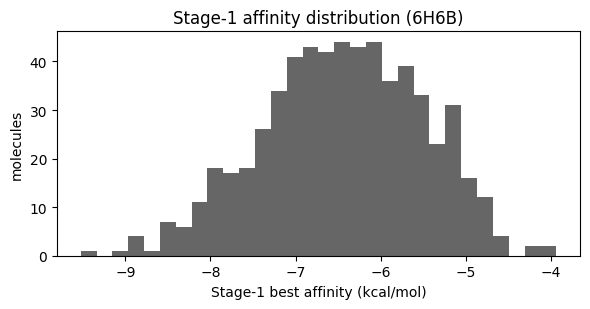

In [10]:
S1_CSV = D_OUT / f"{FILE_PREFIX}stage1_docking.csv"
done = set(pd.read_csv(S1_CSV)["mol_id"]) if S1_CSV.exists() else set()
todo = [r for r in lib.itertuples() if r.mol_id not in done]
workers = max(1, os.cpu_count() or 1)
print(f"{len(done)} already done, {len(todo)} to dock, {workers} parallel Vina jobs, exhaustiveness {CFG['exh1']}")
t_start = time.time()
if todo:
    with ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(dock_job, r.mol_id, r.smiles, r.HA, PRIMARY_PDB, CFG["exh1"], "S1") for r in todo]
        for f in tqdm(as_completed(futs), total=len(futs), desc="Stage-1 docking"):
            append_row(S1_CSV, f.result())
print(f"Stage-1 finished in {(time.time() - t_start) / 60:.1f} min")

s1_all = pd.read_csv(S1_CSV)
print(s1_all["status"].value_counts().to_string())
s1 = lib.merge(s1_all[s1_all.status == "ok"][["mol_id", "affinity", "le", "convergence", "rec_contacts", "region"]], on="mol_id")
FUNNEL.append(("Successfully docked (Stage 1)", len(s1)))
assert len(s1) >= max(3, CFG["n_stage2"]) , "Too few successful dockings - inspect stage1_docking.csv"
s1["aff_n"] = minmax(-s1["affinity"]); s1["le_n"] = minmax(s1["le"])
s1["composite"] = 0.7 * s1["aff_n"] + 0.3 * s1["le_n"]      # affinity is size-biased, so LE gets 30%
s1 = s1.sort_values("composite", ascending=False).reset_index(drop=True)
display(s1[["mol_id", "name", "affinity", "le", "composite"]].head(15))
fig, ax = plt.subplots(figsize=(6, 3.2)); ax.hist(s1["affinity"], bins=30, color="0.4"); ax.set_xlabel("Stage-1 best affinity (kcal/mol)")
ax.set_ylabel("molecules"); ax.set_title(f"Stage-1 affinity distribution ({PRIMARY_PDB})"); plt.tight_layout()
fig.savefig(D_OUT / "fig_stage1_hist.png", dpi=200); plt.show()

## 9 · TOP LIST (10–20) → ONE Stage-2 list
The best `n_stage2` Stage-1 molecules (20 in STANDARD) are chosen by composite score (affinity 70% + ligand efficiency 30%), with a diversity rule (Tanimoto < 0.6 between picks).
**This single list is docked against all three polymorphs. Both Top 3 sets (A and B) are chosen from it.**

PubChem vendor counts show **availability only**. They are not prices.

In [11]:
PUG = "https://pubchem.ncbi.nlm.nih.gov/rest/pug"
CACHE_F = D_OUT / "pubchem_cache.json"
PC = json.loads(CACHE_F.read_text()) if CACHE_F.exists() else {"cid": {}, "vendors": {}}

def cid_from_inchikey(ik):
    if ik in PC["cid"]: return PC["cid"][ik]
    cid = ""
    try:
        r = requests.get(f"{PUG}/compound/inchikey/{ik}/cids/JSON", timeout=30)
        if r.status_code == 200: cid = str(r.json()["IdentifierList"]["CID"][0])
    except Exception: pass
    PC["cid"][ik] = cid; time.sleep(0.25); return cid

def _collect_urls(o, acc):
    if isinstance(o, dict):
        for k, v in o.items():
            if k == "URL" and isinstance(v, str): acc.add(v)
            else: _collect_urls(v, acc)
    elif isinstance(o, list):
        for v in o: _collect_urls(v, acc)

def vendor_count(cid):
    # number of distinct vendor websites in PubChem's "Chemical Vendors" section (availability proxy, NOT a price)
    if not cid: return None
    if cid in PC["vendors"]: return PC["vendors"][cid]
    n = None
    try:
        r = requests.get(f"https://pubchem.ncbi.nlm.nih.gov/rest/pug_view/data/compound/{cid}/JSON?heading=Chemical+Vendors", timeout=45)
        if r.status_code == 404: n = 0
        elif r.status_code == 200:
            urls = set(); _collect_urls(r.json(), urls)
            n = len({urlparse(u).netloc for u in urls if "nlm.nih.gov" not in u and "ncbi" not in u})
    except Exception: pass
    PC["vendors"][cid] = n; time.sleep(0.25); return n

# Synthetic-accessibility score (RDKit Contrib SA_Score); fallback = simple complexity proxy
SA_FN, SA_METHOD = None, "complexity proxy"
try:
    from rdkit.Chem import RDConfig
    sys.path.append(os.path.join(RDConfig.RDContribDir, "SA_Score")); import sascorer
    SA_FN, SA_METHOD = sascorer.calculateScore, "RDKit SA score"
except Exception:
    try:
        d = Path("/content/sa_score"); d.mkdir(exist_ok=True)
        for fn in ("sascorer.py", "fpscores.pkl.gz"):
            if not (d / fn).exists():
                rr = requests.get(f"https://raw.githubusercontent.com/rdkit/rdkit/master/Contrib/SA_Score/{fn}", timeout=60); rr.raise_for_status()
                (d / fn).write_bytes(rr.content)
        sys.path.append(str(d)); import sascorer
        SA_FN, SA_METHOD = sascorer.calculateScore, "RDKit SA score"
    except Exception as e:
        print("SA score unavailable, using complexity proxy:", e)

def sa_score(smi):
    m = Chem.MolFromSmiles(smi)
    if SA_FN is not None:
        try: return float(SA_FN(m))
        except Exception: pass
    n_st = len(Chem.FindMolChiralCenters(m, includeUnassigned=True))
    ri = m.GetRingInfo(); macro = sum(1 for r in ri.AtomRings() if len(r) > 8)
    return float(1 + min(9, 0.1 * m.GetNumHeavyAtoms() + 0.8 * n_st + 1.0 * macro))

# ---- ONE Stage-2 list
stage2_ids = greedy_diverse(s1, CFG["n_stage2"])
FUNNEL.append(("Stage-2 list (3-polymorph docking)", len(stage2_ids)))
print("Stage-2 list size:", len(stage2_ids))

# metadata for every Stage-2 molecule (CID, vendor listing, synthetic accessibility)
meta = s1[s1.mol_id.isin(stage2_ids)].set_index("mol_id").loc[stage2_ids].copy()
meta["cid_final"] = [meta.loc[i, "cid"] or cid_from_inchikey(meta.loc[i, "inchikey"]) for i in meta.index]
meta["vendors"] = [vendor_count(c) for c in tqdm(meta["cid_final"], desc="PubChem vendors")]
meta["sa"] = [sa_score(s) for s in meta["smiles"]]
meta["sa_method"] = SA_METHOD
CACHE_F.write_text(json.dumps(PC))
display(meta[["name", "cid_final", "affinity", "le", "vendors", "sa"]].head(20))

Stage-2 list size: 20


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


PubChem vendors:   0%|          | 0/20 [00:00<?, ?it/s]

,name,cid_final,affinity,le,vendors,sa
mol_id,,,,,,
M02360,pazinaclone,59743,-9.524,0.280118,0.0,3.809302
M01273,dexclamol,91267,-8.542,0.328538,0.0,3.722430
M06162,NaN,,-8.932,0.288129,NaN,3.761767
M06797,pazopanib,,-8.870,0.286129,NaN,3.579427
M00721,fr260010,9968450,-8.489,0.314407,0.0,2.517120
M00394,schembl4036207,19605717,-8.649,0.298241,0.0,3.279014
M00344,fg-8205,129710,-8.272,0.330880,0.0,2.864050
M00621,dehydroevodiamine,9817839,-8.037,0.349435,0.0,2.832477
M00753,compound-s16d,135817291,-8.562,0.295241,0.0,3.203286


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10 · THREE-POLYMORPH DOCKING — the Stage-2 list vs 6H6B, 6CU8, 6RT0
Same box logic, same seed, higher exhaustiveness for every structure so the three numbers are comparable. Resumable.

In [12]:
S2_CSV = D_OUT / f"{FILE_PREFIX}stage2_docking_long.csv"
done2 = set()
if S2_CSV.exists():
    _d = pd.read_csv(S2_CSV); done2 = set(zip(_d.mol_id, _d.pdb_id))
jobs = [(i, p) for i in stage2_ids for p in PDB_IDS if (i, p) not in done2]
print(f"{len(done2)} pairs done, {len(jobs)} to dock, exhaustiveness {CFG['exh2']}")
smi_of = lib.set_index("mol_id")["smiles"].to_dict(); ha_of = lib.set_index("mol_id")["HA"].to_dict()
t0 = time.time()
if jobs:
    with ThreadPoolExecutor(workers) as ex:
        futs = [ex.submit(dock_job, i, smi_of[i], ha_of[i], p, CFG["exh2"], "S2") for i, p in jobs]
        for f in tqdm(as_completed(futs), total=len(futs), desc="Stage-2 docking"):
            append_row(S2_CSV, f.result())
print(f"Stage-2 finished in {(time.time() - t0) / 60:.1f} min")
long = pd.read_csv(S2_CSV); long = long[long.status == "ok"]
complete = long.groupby("mol_id").pdb_id.nunique(); complete = complete[complete == len(PDB_IDS)].index
long = long[long.mol_id.isin(complete) & long.mol_id.isin(stage2_ids)]
print("Molecules docked successfully against all three polymorphs:", long.mol_id.nunique())
assert long.mol_id.nunique() >= 3, "Fewer than 3 molecules completed all three polymorphs"

0 pairs done, 60 to dock, exhaustiveness 24


Stage-2 docking:   0%|          | 0/60 [00:00<?, ?it/s]

Stage-2 finished in 158.6 min
Molecules docked successfully against all three polymorphs: 20


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11 · SCORING — consistency, pose quality, region, ligand efficiency
All sub-scores are scaled 0–1 across the Stage-2 pool (min-max) so the weights mean what they say.

- **affinity:** mean best-pose affinity over the 3 polymorphs (more negative = better)
- **consistency:** smallest max–min affinity range across polymorphs
- **pose:** ½ pose convergence (modes within 2 Å of best) + ½ contacts per heavy atom
- **region:** ½ agreement of the dominant α-syn segment across polymorphs + ½ mean Jaccard overlap of contact residues
- **ligand efficiency:** mean of −affinity/heavy atoms
- **bbb_evidence:** B3DB evidence-group weight

In [13]:
def jaccard(a, b):
    a, b = set(a), set(b); return len(a & b) / len(a | b) if (a | b) else 0.0

rows = []
for mid, g in long.groupby("mol_id"):
    g = g.set_index("pdb_id").loc[PDB_IDS]
    aff = g["affinity"].values
    regs = g["region"].tolist(); top_reg, n_same = Counter(regs).most_common(1)[0]
    sets = [json.loads(x) for x in g["contact_res"]]
    jac = np.mean([jaccard(sets[i], sets[j]) for i in range(3) for j in range(i + 1, 3)])
    res_freq = Counter(r for s in sets for r in s)
    rows.append(dict(mol_id=mid, **{f"aff_{p}": g.loc[p, "affinity"] for p in PDB_IDS},
                     mean_aff=aff.mean(), sd_aff=aff.std(ddof=0), range_aff=aff.max() - aff.min(),
                     conv=g["convergence"].mean(), contacts_per_ha=(g["rec_contacts"] / ha_of[mid]).mean(),
                     le_mean=(-g["affinity"] / ha_of[mid]).mean(), top_region=top_reg, region_agree=n_same / 3.0,
                     region_jac=jac, region_by_pdb="; ".join(f"{p}: {r}" for p, r in zip(PDB_IDS, regs)),
                     top_residues=", ".join(str(r) for r, _ in res_freq.most_common(6))))
F = pd.DataFrame(rows).set_index("mol_id")
F = F.join(meta[["name", "cid_final", "smiles", "group", "evidence", "inchikey", "vendors", "sa", "sa_method", "HA"]])

def add_scores(F, W=W_HP):
    X = pd.DataFrame(index=F.index)
    X["affinity"] = minmax(-F["mean_aff"]); X["consistency"] = minmax(-F["range_aff"])
    X["pose"] = 0.5 * minmax(F["conv"]) + 0.5 * minmax(F["contacts_per_ha"])
    X["region"] = 0.5 * F["region_agree"] + 0.5 * F["region_jac"]
    X["ligand_eff"] = minmax(F["le_mean"]); X["bbb_evidence"] = F["evidence"]
    return X, sum(W[k] * X[k] for k in W)

X, F["overall"] = add_scores(F)
for k in X: F[f"s_{k}"] = X[k]
F = F.sort_values("overall", ascending=False)
display(F[["name", "mean_aff"] + [f"aff_{p}" for p in PDB_IDS] + ["range_aff", "le_mean", "top_region", "overall"]].head(15))
F.to_csv(D_OUT / f"{FILE_PREFIX}stage2_scored_all.csv")

,name,mean_aff,aff_6H6B,aff_6CU8,aff_6RT0,range_aff,le_mean,top_region,overall
mol_id,,,,,,,,,
M00145,chembl1185227,-8.925000,-8.984,-9.754,-8.037,1.717,0.234868,N-term (1-36),0.652197
M00753,compound-s16d,-8.913667,-8.603,-10.265,-7.873,2.392,0.307368,N-term (1-36),0.618143
M06162,NaN,-9.109333,-9.029,-10.183,-8.116,2.067,0.293849,N-term (1-36),0.611509
M00721,fr260010,-8.856333,-8.489,-10.599,-7.481,3.118,0.328012,N-term (1-36),0.580506
M00344,fg-8205,-8.304667,-8.272,-9.631,-7.011,2.620,0.332187,N-term (1-36),0.560005
M00179,risperidone-9-oh,-8.843667,-8.511,-10.305,-7.715,2.590,0.285280,N-term (1-36),0.559999
M02249,tameridone,-8.660000,-8.525,-9.812,-7.643,2.169,0.288667,N-term (1-36),0.520494
M00621,dehydroevodiamine,-8.386333,-8.037,-9.973,-7.149,2.824,0.364623,N-term (1-36),0.507480
M00929,mchr antagonist 23c,-8.564667,-8.831,-9.254,-7.609,1.645,0.237907,N-term (1-36),0.501244


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12 · A. HIGH-PERFORMANCE TOP 3
Picked **only from the computed Stage-2 scores** (sorted by overall computational score, then diversity rule Tanimoto < 0.6). A robustness check re-ranks with 1000 random weight sets to show how stable the top 3 are.

In [14]:
FP.update({i: fp_of(s) for i, s in F["smiles"].items() if i not in FP})
ranked = F.reset_index()
HP_TOP = greedy_diverse(ranked, 3)
assert len(HP_TOP) == 3 and all(i in F.index for i in HP_TOP), "HP top 3 must come from Stage-2 results"

# robustness: random weight vectors
rng = np.random.RandomState(SEED); keys = list(W_HP); hits = Counter()
for _ in range(1000):
    w = dict(zip(keys, rng.dirichlet(np.ones(len(keys)))))
    sc = sum(w[k] * X[k] for k in keys).sort_values(ascending=False)
    for i in sc.index[:3]: hits[i] += 1
F["top3_robustness"] = [hits[i] / 1000 for i in F.index]

def region_text(r): return f"{r.top_region} ({int(round(r.region_agree * 3))}/3 polymorphs); key residues {r.top_residues}; by structure: {r.region_by_pdb}"
def build_table1(ids):
    out = []
    for k, i in enumerate(ids, 1):
        r = F.loc[i]
        out.append({"1. Rank": k, "2. Compound name": r["name"] or "(unnamed in B3DB)", "3. CID": r["cid_final"] or "not found", "4. SMILES": r["smiles"],
                    "5. BBB evidence/label": f"BBB+ (B3DB group {r['group']})",
                    "6. Mean docking affinity (kcal/mol)": round(r.mean_aff, 2),
                    **{f"{7 + j}. Affinity {p} (kcal/mol)": round(r[f"aff_{p}"], 2) for j, p in enumerate(PDB_IDS)},
                    "10. Cross-polymorph consistency": f"SD {r.sd_aff:.2f}; range {r.range_aff:.2f} kcal/mol",
                    "11. Binding/pose region": region_text(r), "12. Ligand efficiency (kcal/mol/HA)": round(r.le_mean, 3),
                    "13. Overall computational score": round(r.overall, 3)})
    return pd.DataFrame(out)

TABLE1 = build_table1(HP_TOP)
print("=" * 70); print("A. HIGH-PERFORMANCE TOP 3  (mode:", MODE, ")"); print("=" * 70)
display(TABLE1.T)
TABLE1.to_csv(D_OUT / f"{FILE_PREFIX}FINAL_A_high_performance_top3.csv", index=False)
print("Robustness (share of 1000 random weightings in which each is top-3):", {i: hits[i] / 1000 for i in HP_TOP})

A. HIGH-PERFORMANCE TOP 3  (mode: STANDARD )


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0,1,2
1. Rank,1,2,3
2. Compound name,chembl1185227,compound-s16d,NaN
3. CID,15986375,135817291,not found
4. SMILES,O=C(c1ccc(C(=O)N2CCN(c3ccc(OC4CCN(C5CCC5)CC4)c...,O=c1[nH]c(C2=CC(N3CCC(c4ccccc4)CC3)CC2)nc2c(Cl...,CC1=CC=CN2C(=O)C(CCN3CCC(c4noc5cc(F)ccc45)CC3)...
5. BBB evidence/label,BBB+ (B3DB group A),BBB+ (B3DB group A),BBB+ (B3DB group C)
6. Mean docking affinity (kcal/mol),-8.92,-8.91,-9.11
7. Affinity 6H6B (kcal/mol),-8.98,-8.6,-9.03
8. Affinity 6CU8 (kcal/mol),-9.75,-10.26,-10.18
9. Affinity 6RT0 (kcal/mol),-8.04,-7.87,-8.12
10. Cross-polymorph consistency,SD 0.70; range 1.72 kcal/mol,SD 1.00; range 2.39 kcal/mol,SD 0.85; range 2.07 kcal/mol


Robustness (share of 1000 random weightings in which each is top-3): {'M00145': 0.6, 'M00753': 0.331, 'M06162': 0.129}


## 13 · COST / PRACTICALITY ANALYSIS
Cost-performance score (transparent):

- **performance** = the same overall computational score used for A
- **availability** = log-scaled count of vendor websites listed by PubChem
- **simplicity** = 1 − (SA score − 1)/9
- **price** = 1 − min-max of log10(price per 100 mg), **only from prices you enter**

Gates (must pass): mean affinity within X kcal/mol of the best HP molecule, ligand efficiency ≥ Y, affinity range ≤ Z, listed by ≥1 vendor, SA ≤ S, and **not** one of the HP Top 3. If fewer than 3 pass, the gates are relaxed step by step and the step used is reported.

### 🔹 Prices — never invented
1. Run the next cell. It writes `price_quotes_TEMPLATE.csv` for the cost shortlist with a PubChem vendor link for each.
2. Look up real quotes from reputable suppliers (e.g. Sigma-Aldrich/Merck, TCI, Cayman, MedChemExpress, Selleck) and fill one row per quote: `mol_id, supplier, catalog_number, pack_size_mg, price, currency, price_date, source_url`. Use **one currency** throughout.
3. Save it as `price_quotes.csv` in the work folder shown above (upload with the Colab file panel), then **re-run the next cell**.
4. Without verified prices the Cost-Effective Top 3 is labelled **PROVISIONAL – price not verified**.

In [15]:
GATE_STEPS = [dict(dmean=1.5, le=0.25, rng=1.5, sa=4.5), dict(dmean=2.0, le=0.22, rng=2.0, sa=5.0), dict(dmean=2.5, le=0.20, rng=2.5, sa=6.0)]
best_hp_mean = F.loc[HP_TOP[0], "mean_aff"]
pool = F[~F.index.isin(HP_TOP)].copy()
pool["avail"] = pool["vendors"].fillna(0).map(lambda v: min(1.0, math.log1p(v) / math.log1p(20)))
pool["simple"] = 1 - (pool["sa"].clip(1, 10) - 1) / 9

gate_used, passed = None, pool.iloc[0:0]
for lvl, g in enumerate(GATE_STEPS, 1):
    ok = pool[(pool.mean_aff <= best_hp_mean + g["dmean"]) & (pool.le_mean >= g["le"]) & (pool.range_aff <= g["rng"]) &
              (pool.vendors.fillna(0) >= 1) & (pool.sa <= g["sa"])]
    if len(ok) >= 3: gate_used, passed = (lvl, g), ok; break
if gate_used is None:
    print("WARNING: fewer than 3 molecules pass even the loosest gates; using the best available by performance.")
    gate_used, passed = (len(GATE_STEPS) + 1, dict(note="fallback: no gates")), pool.sort_values("overall", ascending=False).head(10)
print("Gate level used:", gate_used)

passed = passed.copy()
passed["cp_noprice"] = (W_COST_NOPRICE["performance"] * passed["overall"] + W_COST_NOPRICE["availability"] * passed["avail"]
                        + W_COST_NOPRICE["simplicity"] * passed["simple"])
passed = passed.sort_values("cp_noprice", ascending=False)
SHORT = passed.head(10)

tmpl = pd.DataFrame({"mol_id": SHORT.index, "name": SHORT["name"].values, "cid": SHORT["cid_final"].values,
                     "pubchem_vendor_page": ["https://pubchem.ncbi.nlm.nih.gov/compound/%s#section=Chemical-Vendors" % c if c else "" for c in SHORT["cid_final"]],
                     "supplier": "", "catalog_number": "", "pack_size_mg": "", "price": "", "currency": "", "price_date": "", "source_url": ""})
tmpl.to_csv(D_OUT / "price_quotes_TEMPLATE.csv", index=False)
print("Shortlist written to", D_OUT / "price_quotes_TEMPLATE.csv")
display(tmpl[["mol_id", "name", "cid"]])

# ---- ingest verified prices (if the user supplied them)
PRICE_FILE = next((p for p in [D_OUT / "price_quotes.csv", WORK / "price_quotes.csv", Path("/content/price_quotes.csv")] if p.exists()), None)
price_info = {}
if PRICE_FILE is not None:
    pq = pd.read_csv(PRICE_FILE)
    need = {"mol_id", "supplier", "pack_size_mg", "price", "currency", "price_date", "source_url"}
    assert need <= set(pq.columns), f"price file needs columns {need}"
    pq = pq[pd.to_numeric(pq["price"], errors="coerce").notna() & pd.to_numeric(pq["pack_size_mg"], errors="coerce").notna()].copy()
    pq["price"] = pq["price"].astype(float); pq["pack_size_mg"] = pq["pack_size_mg"].astype(float)
    assert pq["currency"].nunique() <= 1, "Use ONE currency in price_quotes.csv"
    pq["per100"] = pq["price"] / pq["pack_size_mg"] * 100.0           # linear extrapolation to 100 mg
    for mid, g in pq.sort_values("per100").groupby("mol_id"): price_info[mid] = g.iloc[0].to_dict()
    print("Verified quotes loaded for:", list(price_info))

verified_short = [i for i in SHORT.index if i in price_info]
PRICE_MODE = len(verified_short) >= 3
if PRICE_MODE:
    cp = SHORT.loc[verified_short].copy()
    lp = np.log10(pd.Series({i: price_info[i]["per100"] for i in cp.index}))
    cp["price_score"] = minmax(lp, higher_better=False)
    cp["cost_perf"] = (W_COST_PRICE["performance"] * cp["overall"] + W_COST_PRICE["availability"] * cp["avail"]
                       + W_COST_PRICE["simplicity"] * cp["simple"] + W_COST_PRICE["price"] * cp["price_score"])
    cp_pool = cp.sort_values("cost_perf", ascending=False).reset_index()
    COST_LABEL = "VERIFIED PRICES USED"
else:
    cp = SHORT.copy(); cp["price_score"] = np.nan; cp["cost_perf"] = cp["cp_noprice"]
    cp_pool = cp.sort_values("cost_perf", ascending=False).reset_index()
    COST_LABEL = "PROVISIONAL - price not verified"
print("Cost track status:", COST_LABEL)

Gate level used: (4, {'note': 'fallback: no gates'})
Shortlist written to /content/alphasyn_screen/standard/outputs/price_quotes_TEMPLATE.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,mol_id,name,cid
0,M00721,fr260010,9968450
1,M00344,fg-8205,129710
2,M00179,risperidone-9-oh,
3,M02249,tameridone,71304
4,M00477,schembl7481790,22629653
5,M00621,dehydroevodiamine,9817839
6,M01860,pipofezine,159977
7,M00929,mchr antagonist 23c,73226213
8,M02049,panamesine,3047810
9,M06797,pazopanib,


Cost track status: PROVISIONAL - price not verified


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 14 · B. COST-EFFECTIVE TOP 3
Chosen from the **same Stage-2 list**, but ranked by the cost-performance score above (diversity rule applied, A's Top 3 excluded). It is a separate ranking, **not** ranks 4–6 of list A.

In [16]:
COST_TOP = greedy_diverse(cp_pool, 3)
assert len(COST_TOP) == 3 and not set(COST_TOP) & set(HP_TOP) and all(i in F.index for i in COST_TOP)

def build_table2(ids):
    base = build_table1(ids); extra = []
    for i in ids:
        r = F.loc[i]; c = cp.loc[i]; pi = price_info.get(i)
        if pi is not None and PRICE_MODE:
            cost_txt = f"{pi['per100']:.2f} {pi['currency']} per 100 mg (linear from {pi['pack_size_mg']:g} mg pack)"
            src_txt = f"{pi['supplier']}; {pi.get('catalog_number', '')}; checked {pi['price_date']}; {pi['source_url']}"
        else:
            cost_txt, src_txt = "price not verified", "price not verified"
        v = r["vendors"]
        avail = (f"PubChem lists {int(v)} vendor site(s) (checked {CHECK_DATE})" if pd.notna(v) and v >= 1
                 else "no vendor listing found in PubChem - availability not verified")
        delta = r.mean_aff - best_hp_mean
        reason = (f"Mean affinity {r.mean_aff:.2f} kcal/mol ({delta:+.2f} vs best HP molecule); range across polymorphs {r.range_aff:.2f}; "
                  f"LE {r.le_mean:.2f}; {r['sa_method']} {r.sa:.1f} (simple); {avail.split(' (')[0]}; "
                  f"{'verified price used in ranking' if (pi is not None and PRICE_MODE) else 'ranked WITHOUT prices (provisional)'}.")
        extra.append({"14. Estimated acquisition cost": cost_txt, "15. Price/source/date": src_txt, "16. Commercial availability": avail,
                      "17. Cost-performance score": round(float(c["cost_perf"]), 3), "18. Reason selected": reason})
    return pd.concat([base, pd.DataFrame(extra)], axis=1)

TABLE2 = build_table2(COST_TOP)
print("=" * 70); print("B. COST-EFFECTIVE TOP 3  [", COST_LABEL, "]  (mode:", MODE, ")"); print("=" * 70)
display(TABLE2.T)
TABLE2.to_csv(D_OUT / f"{FILE_PREFIX}FINAL_B_cost_effective_top3.csv", index=False)
F.to_csv(D_OUT / f"{FILE_PREFIX}stage2_scored_all.csv")

B. COST-EFFECTIVE TOP 3  [ PROVISIONAL - price not verified ]  (mode: STANDARD )


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,0,1,2
1. Rank,1,2,3
2. Compound name,fr260010,fg-8205,risperidone-9-oh
3. CID,9968450,129710,not found
4. SMILES,Cc1cn(-c2cccc(Nc3ncnc4c3CCc3ccccc3-4)c2)cn1,CC(C)c1nc(-c2ncn3c2CN(C)C(=O)c2c(Cl)cccc2-3)no1,Cc1nc2n(c(=O)c1CCN1CCC(c3coc4cc(F)ccc34)CC1)CC...
5. BBB evidence/label,BBB+ (B3DB group A),BBB+ (B3DB group A),BBB+ (B3DB group A)
6. Mean docking affinity (kcal/mol),-8.86,-8.3,-8.84
7. Affinity 6H6B (kcal/mol),-8.49,-8.27,-8.51
8. Affinity 6CU8 (kcal/mol),-10.6,-9.63,-10.3
9. Affinity 6RT0 (kcal/mol),-7.48,-7.01,-7.72
10. Cross-polymorph consistency,SD 1.30; range 3.12 kcal/mol,SD 1.07; range 2.62 kcal/mol,SD 1.08; range 2.59 kcal/mol


## 15 · AUDIT — provenance checks

In [17]:
checks = {
 "Final tables built from Stage-2 docking results": set(HP_TOP) | set(COST_TOP) <= set(long.mol_id),
 "Each final molecule docked on all 3 polymorphs": all(long[long.mol_id == i].pdb_id.nunique() == 3 for i in HP_TOP + COST_TOP),
 "HP and cost sets are disjoint": not set(HP_TOP) & set(COST_TOP),
 "Cost set was chosen by cost-performance, not by HP rank": all(i in cp_pool.mol_id.values for i in COST_TOP),
 "Library came from BBB+ B3DB entries only": set(lib.mol_id) <= set(pos.mol_id),
 "Stage-1 library size matches mode": len(lib) == min(CFG["n_stage1"], len(cur)),
 "Mode is not SMOKE for scientific use": not IS_SMOKE,
 "Prices entered are all from user-supplied file": all(("price not verified" in str(v)) or PRICE_MODE for v in TABLE2["14. Estimated acquisition cost"]),
}
for k, v in checks.items(): print(("PASS " if v else "FAIL "), k)
if IS_SMOKE: print("\n*** SMOKE MODE: results above are for debugging only and must NOT be reported as scientific findings. ***")

PASS  Final tables built from Stage-2 docking results
PASS  Each final molecule docked on all 3 polymorphs
PASS  HP and cost sets are disjoint
PASS  Cost set was chosen by cost-performance, not by HP rank
PASS  Library came from BBB+ B3DB entries only
PASS  Stage-1 library size matches mode
PASS  Mode is not SMOKE for scientific use
PASS  Prices entered are all from user-supplied file


## 16 · FINAL REPORT (PDF via ReportLab + CSV + figures)
Writes a clean PDF with: the screening funnel, **A. High-Performance Top 3**, **B. Cost-Effective Top 3**, structures, method summary and limitations. Smoke-test runs are stamped **NOT A SCIENTIFIC RESULT** on every page.

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2012: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.style_literal  = oneOf(
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecated - use 'leave_whitespace'
  )("sym").leaveWhitespace()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2024: PyparsingDeprecationWarning: 'oneO

TypeError: 'float' object is not subscriptable

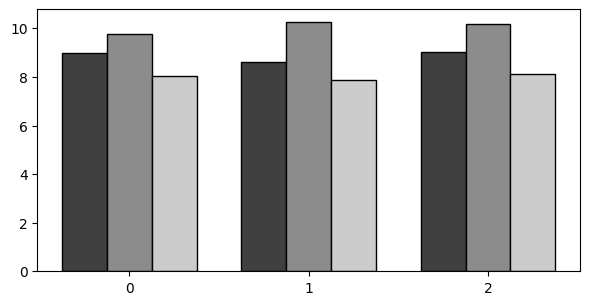

In [18]:
from xml.sax.saxutils import escape
from PIL import Image as PILImage
from reportlab.lib.pagesizes import A4
from reportlab.lib import colors
from reportlab.lib.units import cm
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image as RLImage, PageBreak, KeepTogether

# ---------------- figures ----------------
def savefig(fig, name):
    p = D_OUT / name; fig.savefig(p, dpi=200, bbox_inches="tight"); plt.close(fig); return p

fig, ax = plt.subplots(figsize=(7, 3.4))
labels = [f for f, _ in FUNNEL][::-1]; vals = [v for _, v in FUNNEL][::-1]
ax.barh(labels, vals, color="0.45"); ax.set_xscale("log"); ax.set_xlabel("molecules (log scale)")
for y, v in enumerate(vals): ax.text(v, y, f" {v}", va="center", fontsize=8)
ax.set_title("Screening funnel"); FIG_FUNNEL = savefig(fig, "fig_funnel.png")

def affinity_bar(ids, title, name):
    fig, ax = plt.subplots(figsize=(7, 3.4)); w = 0.25; xs = np.arange(len(ids))
    for j, p in enumerate(PDB_IDS):
        ax.bar(xs + (j - 1) * w, [-F.loc[i, f"aff_{p}"] for i in ids], w, label=p, color=["0.25", "0.55", "0.8"][j], edgecolor="k")
    ax.set_xticks(xs); ax.set_xticklabels([(F.loc[i, "name"] or i)[:18] for i in ids], fontsize=8)
    ax.set_ylabel("−affinity (kcal/mol), higher = stronger"); ax.set_title(title); ax.legend(); return savefig(fig, name)
FIG_A = affinity_bar(HP_TOP, "A. High-performance Top 3 — affinity per polymorph", "fig_A_affinity.png")
FIG_B = affinity_bar(COST_TOP, "B. Cost-effective Top 3 — affinity per polymorph", "fig_B_affinity.png")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(F["mean_aff"], F["overall"], c="0.7", s=20, label="Stage-2 molecules")
ax.scatter(F.loc[HP_TOP, "mean_aff"], F.loc[HP_TOP, "overall"], c="k", s=70, marker="s", label="A. High-performance")
ax.scatter(F.loc[COST_TOP, "mean_aff"], F.loc[COST_TOP, "overall"], c="w", edgecolors="k", s=80, marker="o", linewidths=1.5, label="B. Cost-effective")
ax.set_xlabel("mean docking affinity (kcal/mol)"); ax.set_ylabel("overall computational score"); ax.legend(fontsize=8)
ax.set_title("Where the two Top-3 sets sit"); FIG_MAP = savefig(fig, "fig_map.png")

def structures(ids, legends, name):
    ms = [Chem.MolFromSmiles(F.loc[i, "smiles"]) for i in ids]
    img = Draw.MolsToGridImage(ms, molsPerRow=3, subImgSize=(320, 260), legends=legends)
    p = D_OUT / name; img.save(p); return p
FIG_S_A = structures(HP_TOP, [f"A{k}: {F.loc[i, 'name'] or i}"[:40] for k, i in enumerate(HP_TOP, 1)], "fig_structs_A.png")
FIG_S_B = structures(COST_TOP, [f"B{k}: {F.loc[i, 'name'] or i}"[:40] for k, i in enumerate(COST_TOP, 1)], "fig_structs_B.png")

# ---------------- PDF ----------------
ss = getSampleStyleSheet()
H1 = ParagraphStyle("H1", parent=ss["Heading1"], fontSize=17, spaceAfter=10)
H2 = ParagraphStyle("H2", parent=ss["Heading2"], fontSize=13, spaceBefore=12, spaceAfter=6)
BODY = ParagraphStyle("B", parent=ss["BodyText"], fontSize=9.5, leading=13, spaceAfter=3)
CELL = ParagraphStyle("C", parent=BODY, fontSize=8, leading=10, wordWrap="CJK")
CELLB = ParagraphStyle("CB", parent=CELL, fontName="Helvetica-Bold")
WARN = ParagraphStyle("W", parent=BODY, textColor=colors.black, backColor=colors.Color(0.9, 0.9, 0.9), borderPadding=6, spaceBefore=6, spaceAfter=8)
P = lambda t, s=BODY: Paragraph(escape(str(t)), s)

def rl_img(path, width_cm):
    w, h = PILImage.open(path).size
    return RLImage(str(path), width=width_cm * cm, height=width_cm * cm * h / w)

def bullets(items): return [Paragraph("• " + escape(t), BODY) for t in items]

def overview(tbl):
    hdr = ["Rank", "Compound", "CID", "Mean", PDB_IDS[0], PDB_IDS[1], PDB_IDS[2], "SD", "LE", "Score"]
    rows = [[P(h, CELLB) for h in hdr]]
    for _, r in tbl.iterrows():
        rows.append([P(r["1. Rank"], CELL), P(r["2. Compound name"], CELL), P(r["3. CID"], CELL), P(r["6. Mean docking affinity (kcal/mol)"], CELL)] +
                    [P(r[c], CELL) for c in tbl.columns if c.startswith(("7.", "8.", "9."))] +
                    [P(r["10. Cross-polymorph consistency"].split(";")[0].replace("SD ", ""), CELL),
                     P(r["12. Ligand efficiency (kcal/mol/HA)"], CELL), P(r["13. Overall computational score"], CELL)])
    t = Table(rows, colWidths=[1.0, 4.2, 1.7, 1.4, 1.4, 1.4, 1.4, 1.1, 1.2, 1.5], repeatRows=1)
    t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.4, colors.grey), ("BACKGROUND", (0, 0), (-1, 0), colors.Color(0.88, 0.88, 0.88)),
                           ("VALIGN", (0, 0), (-1, -1), "TOP"), ("TOPPADDING", (0, 0), (-1, -1), 4), ("BOTTOMPADDING", (0, 0), (-1, -1), 4)]))
    return t

def card(row, title):
    data = [[P(k.split(". ", 1)[1], CELLB), P(v, CELL)] for k, v in row.items() if k != "1. Rank"]
    t = Table(data, colWidths=[4.6, 12.4])
    t.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.3, colors.lightgrey), ("VALIGN", (0, 0), (-1, -1), "TOP"),
                           ("BACKGROUND", (0, 0), (0, -1), colors.Color(0.94, 0.94, 0.94)),
                           ("TOPPADDING", (0, 0), (-1, -1), 3), ("BOTTOMPADDING", (0, 0), (-1, -1), 3)]))
    return KeepTogether([Paragraph(escape(title), H2), t, Spacer(1, 8)])

def footer(canvas, doc):
    canvas.saveState(); canvas.setFont("Helvetica", 7.5)
    tag = "SMOKE TEST - NOT A SCIENTIFIC RESULT" if IS_SMOKE else f"Mode: {MODE}"
    canvas.drawString(2 * cm, 1.1 * cm, f"α-Synuclein BBB virtual screen | {tag} | computational prioritisation only")
    canvas.drawRightString(A4[0] - 2 * cm, 1.1 * cm, f"Page {doc.page}"); canvas.restoreState()

story = [Paragraph("α-Synuclein BBB Virtual Screening — Final Report", H1)]
if IS_SMOKE:
    story.append(Paragraph("<b>SMOKE TEST — DEBUG RUN ONLY. NOT A SCIENTIFIC RESULT.</b>", WARN))
story += [Paragraph(escape("Computationally prioritised BBB-positive small molecules proposed for experimental validation of effects on α-synuclein aggregation. "
          "Docking does not prove binding, inhibition, experimental BBB penetration or therapeutic efficacy. These are not Parkinson's treatments or cures."), WARN),
          P(f"Run: {CHECK_DATE} | mode {MODE} | seed {SEED} | RDKit {VERSIONS['rdkit']} | {VERSIONS['vina']} | Meeko {VERSIONS['meeko']}", BODY),
          Paragraph("1. Method in short", H2)]
story += bullets([
    "Start: all BBB-positive entries in B3DB (no smoke subset used for final results).",
    "Clean and filter structures (valid, neutral, drug-like size, no PAINS, de-duplicated).",
    "Rank by an objective relevance score, then pick a diverse Stage-1 library (MaxMin).",
    f"Stage 1: dock the library against {PRIMARY_PDB}. Keep the best by affinity + ligand efficiency.",
    "Stage 2: dock finalists against 6H6B, 6CU8 and 6RT0 with the same settings.",
    "Score: affinity, cross-polymorph consistency, pose quality, region agreement, ligand efficiency, BBB evidence.",
    "A = top overall score. B = separate cost-performance ranking (availability, simplicity, verified prices). B excludes A.",
    "Prices are used only when entered from a real quote. Otherwise: price not verified."])
story += [Spacer(1, 6), rl_img(FIG_FUNNEL, 14), PageBreak()]

story += [Paragraph("A. HIGH-PERFORMANCE TOP 3", H1), overview(TABLE1), Spacer(1, 8), rl_img(FIG_A, 13), Spacer(1, 6), rl_img(FIG_S_A, 15)]
for _, r in TABLE1.iterrows(): story.append(card(r.to_dict(), f"A{r['1. Rank']} — {r['2. Compound name']}"))
story.append(PageBreak())

story += [Paragraph("B. COST-EFFECTIVE TOP 3", H1), Paragraph(escape(f"Status: {COST_LABEL}"), WARN), overview(TABLE2), Spacer(1, 8),
          rl_img(FIG_B, 13), Spacer(1, 6), rl_img(FIG_S_B, 15)]
for _, r in TABLE2.iterrows(): story.append(card(r.to_dict(), f"B{r['1. Rank']} — {r['2. Compound name']}"))
story += [PageBreak(), Paragraph("Where the two sets sit", H2), rl_img(FIG_MAP, 13), Paragraph("Limitations", H2)]
story += bullets([
    "Docking scores are rough estimates. Vina is not accurate for absolute affinity, and fibril surfaces have no single known pocket.",
    "The box covers a central slab of each fibril, not a validated binding site. Hits need confirmation by other methods and by experiment.",
    "Ligand stereochemistry and protonation are taken as-is (neutral forms).",
    "Vendor counts come from PubChem and show listing only, not stock, purity or price.",
    "Pose-quality and region scores are simple heuristics defined in this notebook.",
    "BBB+ labels come from B3DB literature data, not from this work."])
pdf_path = D_OUT / f"{FILE_PREFIX}alpha_synuclein_screen_final_report.pdf"
SimpleDocTemplate(str(pdf_path), pagesize=A4, leftMargin=2 * cm, rightMargin=2 * cm, topMargin=1.8 * cm, bottomMargin=1.8 * cm,
                  title="α-Synuclein BBB virtual screen").build(story, onFirstPage=footer, onLaterPages=footer)

# provenance record
json.dump(dict(mode=MODE, cfg=CFG, versions=VERSIONS, weights_hp=W_HP, cost_status=COST_LABEL, gate=str(gate_used), funnel=FUNNEL,
               hp_top3=HP_TOP, cost_top3=COST_TOP, boxes={p: RECS[p]["box"] for p in PDB_IDS}),
          open(D_OUT / f"{FILE_PREFIX}run_record.json", "w"), indent=2, default=str)
print("PDF:", pdf_path); print("All outputs in:", D_OUT)

## 17 · FINAL LABELLED RESULTS

In [19]:
banner = "SMOKE TEST (DEBUG ONLY - NOT A SCIENTIFIC RESULT)" if IS_SMOKE else f"FINAL RESULTS ({MODE} screen, {len(lib)} Stage-1 molecules)"
display(Markdown(f"# {banner}"))
display(Markdown("## A. HIGH-PERFORMANCE TOP 3")); display(TABLE1.set_index("1. Rank").T)
display(Markdown(f"## B. COST-EFFECTIVE TOP 3  —  *{COST_LABEL}*")); display(TABLE2.set_index("1. Rank").T)
try:
    from google.colab import files
    files.download(str(pdf_path))
except Exception:
    pass

# FINAL RESULTS (STANDARD screen, 600 Stage-1 molecules)

## A. HIGH-PERFORMANCE TOP 3

1. Rank,1,2,3
2. Compound name,chembl1185227,compound-s16d,NaN
3. CID,15986375,135817291,not found
4. SMILES,O=C(c1ccc(C(=O)N2CCN(c3ccc(OC4CCN(C5CCC5)CC4)c...,O=c1[nH]c(C2=CC(N3CCC(c4ccccc4)CC3)CC2)nc2c(Cl...,CC1=CC=CN2C(=O)C(CCN3CCC(c4noc5cc(F)ccc45)CC3)...
5. BBB evidence/label,BBB+ (B3DB group A),BBB+ (B3DB group A),BBB+ (B3DB group C)
6. Mean docking affinity (kcal/mol),-8.92,-8.91,-9.11
7. Affinity 6H6B (kcal/mol),-8.98,-8.6,-9.03
8. Affinity 6CU8 (kcal/mol),-9.75,-10.26,-10.18
9. Affinity 6RT0 (kcal/mol),-8.04,-7.87,-8.12
10. Cross-polymorph consistency,SD 0.70; range 1.72 kcal/mol,SD 1.00; range 2.39 kcal/mol,SD 0.85; range 2.07 kcal/mol
11. Binding/pose region,N-term (1-36) (3/3 polymorphs); key residues 1...,N-term (1-36) (3/3 polymorphs); key residues 1...,N-term (1-36) (2/3 polymorphs); key residues 1...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## B. COST-EFFECTIVE TOP 3  —  *PROVISIONAL - price not verified*

1. Rank,1,2,3
2. Compound name,fr260010,fg-8205,risperidone-9-oh
3. CID,9968450,129710,not found
4. SMILES,Cc1cn(-c2cccc(Nc3ncnc4c3CCc3ccccc3-4)c2)cn1,CC(C)c1nc(-c2ncn3c2CN(C)C(=O)c2c(Cl)cccc2-3)no1,Cc1nc2n(c(=O)c1CCN1CCC(c3coc4cc(F)ccc34)CC1)CC...
5. BBB evidence/label,BBB+ (B3DB group A),BBB+ (B3DB group A),BBB+ (B3DB group A)
6. Mean docking affinity (kcal/mol),-8.86,-8.3,-8.84
7. Affinity 6H6B (kcal/mol),-8.49,-8.27,-8.51
8. Affinity 6CU8 (kcal/mol),-10.6,-9.63,-10.3
9. Affinity 6RT0 (kcal/mol),-7.48,-7.01,-7.72
10. Cross-polymorph consistency,SD 1.30; range 3.12 kcal/mol,SD 1.07; range 2.62 kcal/mol,SD 1.08; range 2.59 kcal/mol
11. Binding/pose region,N-term (1-36) (3/3 polymorphs); key residues 1...,N-term (1-36) (3/3 polymorphs); key residues 1...,N-term (1-36) (3/3 polymorphs); key residues 1...


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
